# Student employment, origin and education

Reproducible analysis of the three supplied CSV files. Run all cells from this folder. Install `requirements.txt` in your Python environment first. See [methods and limitations](README.html) and [interactive analysis](index.html). No geocoding requests or student data are sent to external services.

**Interpretation:** current means current in the historical source. Recorded education years do not establish continuous attendance. Missing career records do not establish unemployment.

## 1. Source validation

Read the source files with their actual delimiters. Validate the person and appointment keys and record hashes. Main and career use semicolons; education uses commas.

In [1]:
from pathlib import Path
import json, hashlib, itertools, shutil
import pandas as pd
import numpy as np
import networkx as nx

ROOT = Path.cwd()
if not (ROOT / 'data/main.csv').exists():
    ROOT = Path(__file__).resolve().parent
DATA = ROOT / 'data'
TABLES = ROOT / 'tables'
TABLES.mkdir(exist_ok=True)
UNKNOWN = 'Unknown'
main = pd.read_csv(DATA / 'main.csv', sep=';')
educ = pd.read_csv(DATA / 'educ.csv')
career = pd.read_csv(DATA / 'career.csv', sep=';')
birth_lookup = pd.read_csv(DATA / 'chinese_cities_with_coordinates.csv', sep=';', dtype=str)
def tidy(df):
    df = df.loc[:, ~df.columns.str.startswith('Unnamed:')].copy()
    for c in df.select_dtypes('object'):
        df[c] = df[c].str.strip().replace('', np.nan)
    return df
main, educ, career = map(tidy, [main, educ, career])
assert main.NameID.notna().all() and main.NameID.is_unique
assert career.record_id.notna().all() and career.record_id.is_unique
assert set(educ.NameID) <= set(main.NameID)
assert set(career.NameID) <= set(main.NameID)
manifest = [{'file':p.name,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()} for p in DATA.glob('*.csv') if p.name in ['main.csv','educ.csv','career.csv','chinese_cities_with_coordinates.csv']]
pd.DataFrame(manifest).to_csv(TABLES / 'source_manifest.csv', index=False)
print(f'Source rows: {len(main):,} students; {len(educ):,} education records; {len(career):,} appointments.')

Source rows: 1,613 students; 3,151 education records; 1,689 appointments.


## 2. Synthetic student list

Aggregate education before joining career to avoid multiplying appointment rows. Recorded study years are observations, not complete attendance dates. Gender comes from main; disagreement is audited.

The education filter uses unique nonmissing `educ.Level` values (for example Bachelor, Master and Doctor), rather than raw Degree labels. Source Level categories are preserved; Unknown selects students with no recorded level. Raw degrees remain in the exports for reference. Birthplace coordinates are joined from the supplied lookup with a match audit.

In [2]:
educ['Year'] = pd.to_numeric(educ.Year, errors='coerce')
education_summary = educ.groupby('NameID').agg(study_start=('Year','min'), study_end=('Year','max'), education_records=('NameID','size'))
students = main.merge(education_summary, on='NameID', how='left', validate='one_to_one')
students['education_records'] = students.education_records.fillna(0).astype(int)
def unique_values(s):
    return sorted(set(str(v) for v in s.dropna()))
for src, dest in [('University_clean','education_institutions'),('Degree','degrees'),('Level','education_levels'),('discipline','disciplines'),('Country','education_countries')]:
    vals = educ.groupby('NameID')[src].agg(unique_values)
    students[dest] = students.NameID.map(vals).map(lambda x: x if isinstance(x,list) else [])
education_gender = educ.groupby('NameID').Gender.agg(unique_values)
students['education_gender_values'] = students.NameID.map(education_gender).map(lambda x: x if isinstance(x,list) else [])
students['gender_conflict'] = students.apply(lambda r: bool(r.Gender and any(x != r.Gender for x in r.education_gender_values)), axis=1)
students['Gender'] = students.Gender.fillna(UNKNOWN)
def decade(s):
    return s.map(lambda x: f'{int(x)//10*10}s' if pd.notna(x) else UNKNOWN)
students['birth_decade'] = decade(students.birth_year)
students['study_start_decade'] = decade(students.study_start)
students['study_end_decade'] = decade(students.study_end)
def export(df, name):
    out = df.copy()
    for c in out:
        if out[c].map(lambda v:isinstance(v,list)).any(): out[c] = out[c].map(lambda v:json.dumps(v,ensure_ascii=False) if isinstance(v,list) else v)
    out.to_csv(TABLES / (name+'.csv'), index=False, encoding='utf-8-sig')
from geocode_birthplaces import geocode_birthplaces
birth_geocodes,parsed_lookup=geocode_birthplaces(main,birth_lookup)
derived=[c for c in birth_geocodes if c not in main.columns or c=='NameID']
students=students.merge(birth_geocodes[derived],on='NameID',how='left',validate='one_to_one')
export(birth_geocodes,'birthplace_geocodes')
export(birth_geocodes.loc[birth_geocodes.birth_geocode_status.ne('matched')],'unmapped_birth_towns')
export(birth_geocodes.loc[birth_geocodes.birth_geocode_status.eq('ambiguous')],'ambiguous_birth_towns')
export(parsed_lookup,'birth_coordinate_lookup_parsed')
export(students, 'students_synthetic')
jobs = career.merge(students, on='NameID', how='left', validate='many_to_one', indicator=True)
assert len(jobs) == len(career) and jobs._merge.eq('both').all()
jobs = jobs.drop(columns='_merge')
rename = {'Institution_normalized':'employer','institution_sector':'sector','Position_normalized':'position','professional_group_valid':'group','advancement_level_valid':'level','appointment_status_normalized':'status','City_completed':'city','State_province_completed':'province','Country_completed':'country','Gender':'gender'}
jobs = jobs.rename(columns=rename)
for col in ['employer','sector','position','group','level','status','city','province','country','gender','Birth_province_py_st']:
    jobs[col] = jobs[col].fillna(UNKNOWN)
jobs['country'] = jobs.country.replace({'USA':'United States'})
jobs['status'] = jobs.status.replace({'Former':'Past'})
# Explicit, geographically unambiguous corrections. Preserve source province separately.
jobs['province_source'] = jobs.province
state_aliases = {'Chicago':'Illinois','Pittsburgh':'Pennsylvania','Southern California':'California','South California':'California'}
us = jobs.country.eq('United States')
jobs.loc[us,'province'] = jobs.loc[us,'province'].replace(state_aliases)
export(jobs.loc[jobs.province.ne(jobs.province_source),['record_id','province_source','province']], 'state_corrections')
jobs['valid_coordinates'] = jobs.latitude.between(-90,90) & jobs.longitude.between(-180,180)
export(jobs, 'career_joined')
export(educ, 'education_clean')
export(students[students.gender_conflict], 'gender_conflicts')
print(f'Joined appointments: {len(jobs):,}; distinct people with appointments: {jobs.NameID.nunique():,}.')

Joined appointments: 1,689; distinct people with appointments: 931.


In [3]:
students[["NameID","Gender","birth_year","study_start","study_end","education_levels","disciplines"]].head(12)

,NameID,Gender,birth_year,study_start,study_end,education_levels,disciplines
0,N00001,F,1918.0,1943.0,1943.0,[],[Nursing]
1,N00002,F,NaN,1943.0,1943.0,[],[Chemistry]
2,N00003,M,1919.0,1939.0,1943.0,[],[Economics]
3,N00004,F,NaN,1943.0,1943.0,[],[Accounting]
4,N00005,M,NaN,1940.0,1942.0,[Master],[Business]
5,N00006,M,NaN,1943.0,1943.0,[],[Civil Engineering]
6,N00007,F,NaN,1943.0,1943.0,[],[Medicine]
7,N00008,M,NaN,1940.0,1940.0,[],[Aeronautical Engineering]
8,N00009,M,NaN,1941.0,1943.0,[Bachelor],"[Biochemistry, Botany]"
9,N00010,M,1918.0,1943.0,1943.0,[Doctor],[Medicine]


## 3. Descriptive tables

Count appointment records and distinct people, preserving unknowns. Educational-background categories can overlap. Students without career records remain in the source-coverage denominators; missing career data do not establish unemployment.

In [4]:
def counts(df, columns):
    return df.groupby(columns,dropna=False).agg(appointments=('record_id','size'),students=('NameID','nunique'),employers=('employer',lambda s:s[s.ne(UNKNOWN)].nunique())).reset_index().sort_values('appointments',ascending=False)
for dim in ['sector','employer','position','level','group']:
    export(counts(jobs,[dim]), f'{dim}_overall')
    for by in ['status','gender','birth_decade','study_start_decade','study_end_decade','Birth_province_py_st']:
        export(counts(jobs,[by,dim]),f'{dim}_by_{by}')
    export(counts(jobs,['status','gender','birth_decade','study_start_decade',dim]),f'{dim}_combined_strata')
for dim in ['sector','employer']:
    export(counts(jobs,['level',dim]),f'{dim}_by_position_level')
for cols,name in [(['country'],'jobs_by_country'),(['country','province'],'jobs_by_province'),(['country','province','city'],'jobs_by_city')]:
    export(counts(jobs,cols),name)
for attr in ['degrees','education_levels','disciplines','education_institutions','education_countries']:
    exploded = jobs.explode(attr)
    exploded[attr] = exploded[attr].fillna(UNKNOWN)
    for dim in ['sector','level','status']:
        export(counts(exploded,[attr,dim]),f'{dim}_by_{attr}')
# Student denominators include those without any recorded appointment. These are source coverage, not unemployment rates.
coverage = students.copy()
coverage['has_career_record'] = coverage.NameID.isin(jobs.NameID)
coverage['has_current_record'] = coverage.NameID.isin(jobs.loc[jobs.status.eq('Current'),'NameID'])
for by in ['Gender','Birth_province_py_st','birth_decade','study_start_decade']:
    t=coverage.groupby(by,dropna=False).agg(students=('NameID','size'),with_career_record=('has_career_record','sum'),with_current_record=('has_current_record','sum')).reset_index()
    t['career_record_coverage_pct']=100*t.with_career_record/t.students
    export(t,f'student_coverage_by_{by}')
missing = pd.concat([d.isna().sum().rename(n) for d,n in [(main,'main'),(educ,'educ'),(career,'career')]],axis=1).rename_axis('field').reset_index()
export(missing,'missingness')
metrics = {'students':len(students),'education_records':len(educ),'appointments':len(jobs),'people_with_appointments':jobs.NameID.nunique(),'students_without_appointments':len(students)-jobs.NameID.nunique(),'birth_year_known':int(students.birth_year.notna().sum()),'study_year_known':int(students.study_start.notna().sum()),'geocoded_appointments':int(jobs.valid_coordinates.sum()),'past_appointments':int(jobs.status.eq('Past').sum()),'current_appointments':int(jobs.status.eq('Current').sum()),'unknown_status_appointments':int(jobs.status.eq(UNKNOWN).sum()),'known_employers':jobs.loc[jobs.employer.ne(UNKNOWN),'employer'].nunique(),'gender_conflicts':int(students.gender_conflict.sum())}
export(pd.DataFrame(metrics.items(),columns=['metric','value']),'summary_metrics')
print(json.dumps(metrics,indent=2))

{
  "students": 1613,
  "education_records": 3151,
  "appointments": 1689,
  "people_with_appointments": 931,
  "students_without_appointments": 682,
  "birth_year_known": 488,
  "study_year_known": 1496,
  "geocoded_appointments": 1056,
  "past_appointments": 969,
  "current_appointments": 710,
  "unknown_status_appointments": 10,
  "known_employers": 760,
  "gender_conflicts": 0
}


In [5]:
counts(jobs,["sector"]).head(12)

,sector,appointments,students,employers
0,Academic / education,495,337,170
3,Government / public administration,330,242,126
5,Industry / manufacturing / extraction,209,174,138
9,Military / defense,186,126,47
1,Business / commerce,79,73,51
2,Finance / banking / insurance,68,62,23
15,Transport / utilities / communications,64,51,44
12,Professional services,55,48,36
8,Media / publishing / entertainment,52,39,38
10,Non-state / nonprofit organization,48,43,25


## 4. Networks

Deduplicate person–employer affiliations before constructing networks. Projection weights count distinct shared people. Communities use weighted greedy modularity on the full network; interactive degree filters use the graph after appointment filters.

Both network HTML views offer ongoing physics with a 0.25×–2× pace slider and Pause/Resume. Paused/running state and pace persist across filters; retained nodes reuse their positions. The shared control helpers are in assets/ui_helpers.js. Layout motion does not change graph counts or centralities.

In [6]:
# Unknown employers remain in descriptive tables but cannot identify a shared institution.
aff = jobs.loc[jobs.employer.ne(UNKNOWN),['NameID','employer']].drop_duplicates()
B = nx.Graph()
B.add_nodes_from(('p:'+p,{'kind':'student'}) for p in aff.NameID.unique())
B.add_nodes_from(('e:'+e,{'kind':'employer'}) for e in aff.employer.unique())
B.add_edges_from(('p:'+r.NameID,'e:'+r.employer) for r in aff.itertuples())
people=set(n for n,d in B.nodes(data=True) if d['kind']=='student')
employers=set(B)-people
bc = nx.algorithms.bipartite.degree_centrality(B,people)
export(pd.DataFrame([{'node':n,'kind':B.nodes[n]['kind'],'degree':B.degree(n),'opposite_partition_centrality':bc[n]} for n in sorted(B)]),'bipartite_nodes')
export(aff,'bipartite_edges')
G = nx.Graph()
G.add_nodes_from(sorted(aff.employer.unique()))
edge_people={}
for person,group in aff.groupby('NameID'):
    for a,b in itertools.combinations(sorted(group.employer),2):
        edge_people.setdefault((a,b),set()).add(person)
G.add_weighted_edges_from((a,b,len(ps)) for (a,b),ps in edge_people.items())
communities=nx.community.greedy_modularity_communities(G,weight='weight') if G.number_of_edges() else [{n} for n in G]
community={n:i+1 for i,c in enumerate(sorted(communities,key=lambda c:(-len(c),min(c)))) for n in c}
dc=nx.degree_centrality(G)
export(pd.DataFrame([{'employer':n,'degree':G.degree(n),'degree_centrality':dc[n],'strength':G.degree(n,weight='weight'),'community':community[n]} for n in sorted(G)]),'employer_nodes')
export(pd.DataFrame([{'source':a,'target':b,'shared_students':len(ps),'NameIDs':'|'.join(sorted(ps))} for (a,b),ps in edge_people.items()]),'employer_edges')
print(f'Bipartite: {B.number_of_nodes()} nodes, {B.number_of_edges()} edges. Employer projection: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges; {len(communities)} communities.')

Bipartite: 1687 nodes, 1592 edges. Employer projection: 760 nodes, 986 edges; 255 communities.


In [7]:
pd.read_csv(TABLES / "employer_nodes.csv").sort_values("degree",ascending=False).head(12)

,employer,degree,degree_centrality,strength,community
457,National Resources Commission,58,0.076416,68,1
664,Universal Trading Corporation,38,0.050066,40,4
355,Jiaotong University,29,0.038208,31,1
634,Tsinghua University,28,0.036891,33,3
138,Chinese Ministry of Communications,26,0.034256,33,4
721,Yenching University,25,0.032938,26,3
442,National Central University,23,0.030303,25,1
385,Lingnan University,19,0.025033,22,2
7,Aeronautical Commission,18,0.023715,18,5
612,Sun Yat-sen University,18,0.023715,18,2


## 5. Geography and association routes

Match birth towns to `data/chinese_cities_with_coordinates.csv` by province plus the Chinese or romanized town label, using Unicode/case/punctuation normalization. Decimal commas in coordinates are parsed explicitly. Conflicting coordinates are not guessed. All 919 recorded birth localities match the lookup; 694 students have no birth town. Seven matched entries are province proxies explicitly noted in the lookup, and remain labelled as such. The original locality notes and lookup row IDs are retained in route exports and tooltips.

Each mapped appointment is weighted equally over the person’s distinct mapped education stops. Missing birth coordinates do not suppress education-to-work links.

In [8]:
def loadgeo(name): return json.loads((ROOT/'assets'/name).read_text())
world=loadgeo('world.geojson'); usgeo=loadgeo('us_states.geojson'); cngeo=loadgeo('china_provinces.geojson')
cnnames={'11':'Beijing','12':'Tianjin','13':'Hebei','14':'Shanxi','15':'Inner Mongolia','21':'Liaoning','22':'Jilin','23':'Heilongjiang','31':'Shanghai','32':'Jiangsu','33':'Zhejiang','34':'Anhui','35':'Fujian','36':'Jiangxi','37':'Shandong','41':'Henan','42':'Hubei','43':'Hunan','44':'Guangdong','45':'Guangxi','46':'Hainan','50':'Chongqing','51':'Sichuan','52':'Guizhou','53':'Yunnan','54':'Tibet','61':'Shaanxi','62':'Gansu','63':'Qinghai','64':'Ningxia','65':'Xinjiang','71':'Taiwan','81':'Hong Kong','82':'Macao'}
for f in cngeo['features']:
    f['properties']['name_en']=cnnames.get(str(f['properties']['id']),f['properties']['name'])
for geo,country,ncol,out in [(usgeo,'United States','name','us_state_counts'),(cngeo,'China','name_en','china_province_counts')]:
    valid={f['properties'][ncol] for f in geo['features']}
    subset=jobs.loc[jobs.country.eq(country)]
    allcounts=counts(subset,['province'])
    allcounts['matched_boundary']=allcounts.province.isin(valid)
    export(allcounts,out)
    export(subset.loc[~subset.province.isin(valid),['record_id','NameID','country','province','city']],out+'_unmatched')
export(jobs.loc[~jobs.valid_coordinates,['record_id','NameID','country','province','city']],'unmapped_appointments')
educ['lat'] = educ.latitude_revised.combine_first(educ.Latitude)
educ['lon'] = educ.longitude_revised.combine_first(educ.Longitude)
educ['valid_coordinates']=educ.lat.between(-90,90)&educ.lon.between(-180,180)
# A location is an educational stop, not a dated visit; collapse repeated same-school coordinates per person.
edu_stops=educ.loc[educ.valid_coordinates,['NameID','University_clean','City','Province_State','Country','lat','lon']].drop_duplicates()
routes=[]
for r in jobs.loc[jobs.valid_coordinates].itertuples():
    stops=edu_stops.loc[edu_stops.NameID.eq(r.NameID)]
    for e in stops.itertuples():
        routes.append({'record_id':r.record_id,'NameID':r.NameID,'birth_province':r.Birth_province_py_st,'birth_town_py':r.Birth_town_py,'birth_town_zh':r.Birth_town_zh,'birth_lon':r.birth_lon,'birth_lat':r.birth_lat,'birth_geocode_status':r.birth_geocode_status,'birth_coordinate_precision':r.birth_coordinate_precision,'birth_coordinate_notes':r.birth_coordinate_notes,'birth_lookup_ids':r.birth_lookup_ids,'education':e.University_clean,'education_city':e.City,'education_lon':e.lon,'education_lat':e.lat,'work_city':r.city,'work_lon':r.longitude,'work_lat':r.latitude,'weight':1/len(stops)})
routes=pd.DataFrame(routes)
export(routes,'birth_education_work_routes')
stale=TABLES/'unmapped_birth_provinces.csv'
if stale.exists():stale.unlink()
print(f'Birthplace lookup: {students.birth_geocode_status.value_counts().to_dict()}')
print(f'Route rows: {len(routes):,}; weights total {routes.weight.sum():.0f} appointment equivalents. Birth coordinates come from the supplied town lookup, with its precision notes retained.')

Birthplace lookup: {'matched': 919, 'missing_town': 694}
Route rows: 2,097; weights total 1044 appointment equivalents. Birth coordinates come from the supplied town lookup, with its precision notes retained.


## 6. Direct past-to-current employer Sankey

Two stages link past employers directly to current employers. Each link counts distinct individuals whose matching records include both employers. Repeated appointment rows are deduplicated. A person with multiple employers can bridge several pairs, so link counts are not additive unique-person totals. Link tooltips and CSV exports retain bridging NameIDs and names. Filtering rebuilds employer pairs and counts from surviving appointment records. When Other groups are enabled, people are deduplicated within each displayed grouped pair. No appointment dates are available, so these are status-based associations rather than verified successive job moves.

In [9]:
# Past and current employer sets are not chronologically ordered within each status.
# Each person contributes once to every distinct past/current employer pair they bridge.
pair_people={}
person_labels=jobs.groupby('NameID').NameFull.first().to_dict()
for person,g in jobs.groupby('NameID'):
    past=sorted(set(g.loc[g.status.eq('Past'),'employer'])-{UNKNOWN})
    current=sorted(set(g.loc[g.status.eq('Current'),'employer'])-{UNKNOWN})
    if not past or not current: continue
    for a,b in itertools.product(past,current):pair_people.setdefault((a,b),set()).add(person)
sankey_links=pd.DataFrame([{'source':'Past: '+a,'target':'Current: '+b,'weight':len(ps),'individuals':len(ps),'NameIDs':sorted(ps),'individual_names':[p+' · '+person_labels.get(p,p) for p in sorted(ps)]} for (a,b),ps in sorted(pair_people.items())])
export(sankey_links,'sankey_links')
sankey_bridges=pd.DataFrame([{'past_employer':a,'current_employer':b,'NameID':p,'NameFull':person_labels.get(p,p)} for (a,b),ps in sorted(pair_people.items()) for p in sorted(ps)])
export(sankey_bridges,'sankey_individual_bridges')
print(f'Sankey includes {sankey_bridges.NameID.nunique()} distinct people bridging {len(sankey_links)} past–current employer pairs. Link counts are not additive unique-person totals.')

Sankey includes 330 distinct people bridging 552 past–current employer pairs. Link counts are not additive unique-person totals.


## 7. Interactive exports and reconciliation

Rebuild the HTML files using the bundled JavaScript, CSS, boundaries and analysis data. Each exported HTML contains its required assets and data. Browser logic is in assets/app.js for review. All data and labels remain local.

In [10]:
def records(df): return json.loads(df.to_json(orient='records',force_ascii=False))
client_cols=['record_id','NameID','NameFull','employer','sector','position','group','level','status','city','province','country','gender','birth_year','study_start','study_end','birth_decade','study_start_decade','study_end_decade','Birth_province_py_st','degrees','education_levels','disciplines','education_countries','education_institutions','latitude','longitude','valid_coordinates']
payload={'jobs':records(jobs[client_cols]),'students':records(students[['NameID','Birth_province_py_st','education_levels','disciplines','education_countries']]),'routes':records(routes),'communities':community,'metrics':metrics,'world':world,'us':usgeo,'china':cngeo}
(ROOT/'assets'/'analysis_data.js').write_text('window.ANALYSIS='+json.dumps(payload,ensure_ascii=False,separators=(',',':'))+';',encoding='utf-8')
from render_html import build_pages
build_pages(ROOT,metrics)
assert len(students)==main.NameID.nunique()
assert jobs.record_id.is_unique and len(jobs)==len(career)
assert jobs.groupby('status').size().sum()==len(career)
assert abs(routes.weight.sum()-jobs.loc[jobs.valid_coordinates & jobs.NameID.isin(edu_stops.NameID)].shape[0])<1e-8
assert G.number_of_edges()==len(edge_people)
checks={'student_key_unique':True,'career_join_preserves_rows':True,'status_counts_reconcile':True,'route_weights_reconcile':True,'projection_edges_reconcile':True,'unmatched_main_ids':0,'gender_conflicts':metrics['gender_conflicts']}
(ROOT/'validation.json').write_text(json.dumps(checks,indent=2))
print('Exports and reconciliation checks completed.')

Exports and reconciliation checks completed.


## 8. Static choropleths

Generate the PNG/SVG reference figure and show it below. Interactive choropleths remain available in maps/choropleths.html.

Saved static choropleths (PNG and SVG).


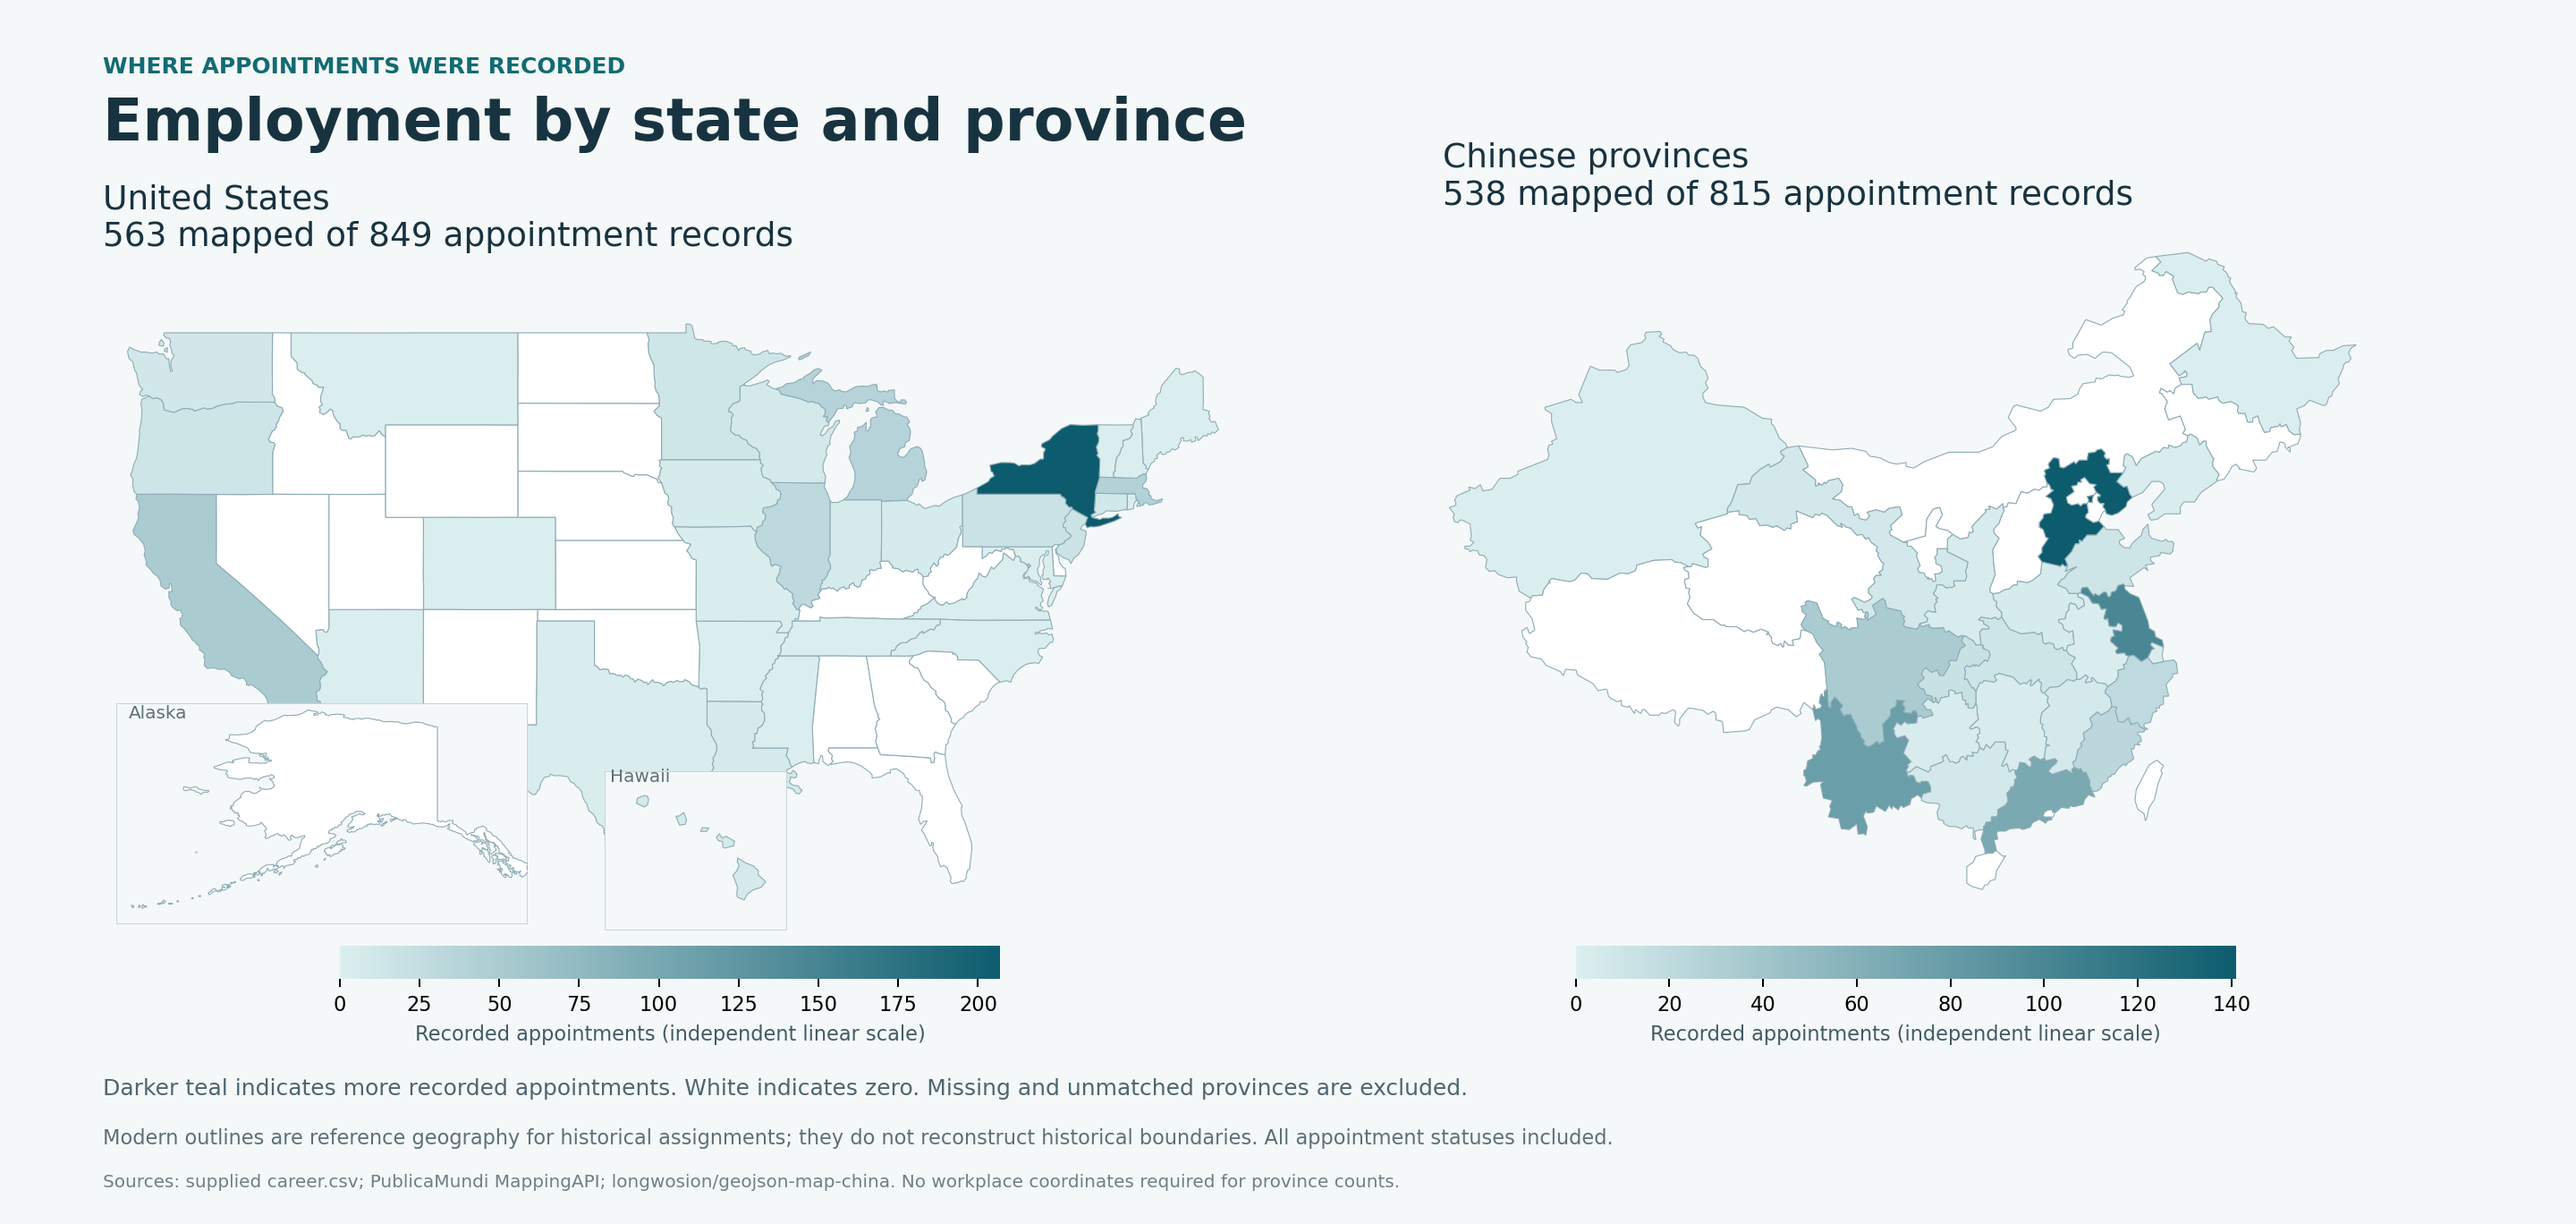

In [11]:
import runpy
runpy.run_path(str(ROOT / 'static_maps.py'), run_name='__main__')
from IPython.display import Image, display
display(Image(filename=str(ROOT / 'maps/choropleths.png'), width=1100))

## 9. Independent filter and graph checks

Compare exact browser-side pure-data functions with pandas/NetworkX reference results. Tests cover all filter scenarios, distinct-person counts and identities on direct past/current links, grouping without duplicate people, repeated appointments, network measures and text-element network tooltips. Node.js is required for these optional JavaScript checks. Birthplace checks use the supplied lookup. These are code/data tests; interactive browser rendering was not visually verified.

In [12]:
import subprocess, sys, shutil
subprocess.run([sys.executable, str(ROOT / 'validate_filters.py')], check=True)
node = shutil.which('node')
if node:
    result = subprocess.run([node, str(ROOT / 'validate_filters.cjs')], check=True, capture_output=True, text=True)
    print(result.stdout)
else:
    print('Node.js not installed; browser-side logic checks skipped. Run node validate_filters.cjs after installing Node.js.')
subprocess.run([sys.executable, str(ROOT / "validate_birthplaces.py")], check=True)

{
  filter_scenarios_passed: 27,
  bipartite_degree_and_centrality_matches_python: true,
  projection_degree_and_centrality_matches_python: true,
  direct_sankey_filter_scenarios_match_python: 27,
  direct_links_have_no_individual_stage: true,
  distinct_bridge_people_and_names_verified: true,
  other_groups_deduplicate_individuals: true,
  repeated_appointments_do_not_inflate_bridges: true,
  network_node_and_edge_tooltips_use_text_elements: true,
  browser_visual_preview: 'blocked by local file URL security policy'
}



CompletedProcess(args=['/Users/carmand/.cache/codex-runtimes/codex-primary-runtime/dependencies/python/bin/python3', '/Users/carmand/Documents/Codex/2026-10-25/given-the-three-following-files-i-3/outputs/validate_birthplaces.py'], returncode=0)

## Open the outputs

[Overview and tables](index.html) · [City circles](maps/cities.html) · [Choropleths](maps/choropleths.html) · [Association flows](maps/flows.html) · [Two-mode network](networks/individual_employer.html) · [Employer projection](networks/employer_projection.html) · [Sankey](sankey/employers.html)

Every view supports simultaneous multiple selections and period filtering with unknown years. Graph and Sankey calculations recalculate locally after filters. The static CSVs remain the unfiltered reference exports. The browser preview was blocked in the authoring session; see README for verification scope.